<a href="https://colab.research.google.com/github/fxrdhan/Practical-Statistics-for-Data-Scientists/blob/main/Chapter_07_Unsupervised_Learning/Chapter_07_Unsupervised_Learning.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Chapter 7 — Unsupervised Learning

| | |
|---|---|
| **Book** | *Practical Statistics for Data Scientists: 50+ Essential Concepts Using R and Python*, 2nd edition — Peter Bruce, Andrew Bruce and Peter Gedeck (O'Reilly Media, 2020) |
| **Code reproduced here** | the Python code of the book's official repository, `gedeck/practical-statistics-for-data-scientists` (GNU General Public License v3) |
| **Versions used to run this notebook** | printed by the setup cell |
| **What this notebook contains** | a summary of every section of the chapter, the theory behind it, the book's Python code reproduced and executed, and a short analysis of the outputs |

## Chapter overview

In **unsupervised learning** there is no outcome variable to predict: the methods look for structure in the predictors alone, and their purpose is to summarize the data, to discover groups, or to prepare variables for later modelling. The chapter has four families of methods. **Principal components analysis** (and its relative for categorical data, **correspondence analysis**) replaces many correlated numeric variables by a few new ones that keep most of the information. **K-means** divides the records into a chosen number of clusters around centres. **Hierarchical clustering** builds a whole tree of nested clusters, drawn as a **dendrogram**, from which any number of clusters can be read. **Model-based clustering** assumes that the data come from a mixture of normal distributions and fits it, which gives probabilities of membership and a statistical criterion for the number of clusters. The last section deals with what every distance-based method needs: **variables on comparable scales**, and a way to handle **categorical variables** (Gower's distance).

### Sections of this chapter

| # | Section of the book | Python code in the book |
|---|---|---|
| 1 | Principal components analysis | two stocks, sixteen stocks (scree plot, loadings), correspondence analysis of household tasks |
| 2 | K-means clustering | two stocks, sixteen stocks (cluster sizes, centres), the number of clusters |
| 3 | Hierarchical clustering | eighteen stocks (dendrogram), four measures of dissimilarity |
| 4 | Model-based clustering | the multivariate normal distribution, a mixture of two normals, BIC for the number of clusters |
| 5 | Scaling and categorical variables | scaling the loan data, dominant variables, mixed data |

### How to read this notebook

Every section has the same structure: a **Summary** (what the book says, condensed in my own words; the book itself is not quoted), the **Theory** behind the section, the **Book code** (the official Python code of the chapter, reproduced and executed) and a short **Output analysis**.

Every code cell starts with a label comment: `# BOOK CODE` for code of the official repository (the setup cell is labelled `# SETUP` and is not part of the book). The book's code is reproduced as it is; the cells that draw random numbers without a seed in the script start with a seeding line marked `# NOT IN THE BOOK`, so that every run gives the same output.

---
## 0. Setup

The datasets of the book live in the official repository, in its `data` folder. The helper `ensure_data` below looks for each file in a folder called `data` next to the notebook and **downloads it from the official repository the first time** it is missing (this is the only use of the network; the folder is not part of this repository, see `.gitignore`). The files of this chapter are `sp500_data.csv.gz` (the daily price changes of 517 stocks of the S&P 500 index from 1993 to 2015), `loan_data.csv.gz` (45,342 loans, half of them in default), `housetasks.csv` (a table of counts: who does which household task) and `sp500_sectors.csv` (the sector of each stock; the script defines its path but does not use it).

The setup cell also prints the versions of the libraries, because the code of the book was written for older ones. The packages `prince` (correspondence analysis) and `adjustText` (non-overlapping labels in a plot) are not part of a standard Python installation; the cell installs them if they are missing (a fresh environment, or Google Colab, may not have them).

In [1]:
# SETUP
import importlib.util
import platform
import subprocess
import sys
import urllib.request
import warnings
from pathlib import Path

# a fresh environment may not have `prince` (correspondence analysis) or `adjustText` (labels of the plot); install them when they are missing
for package in ["prince", "adjustText"]:
    if importlib.util.find_spec(package) is None:
        subprocess.check_call([sys.executable, "-m", "pip", "install", "-q", package])

import adjustText
import matplotlib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import prince
import scipy
import seaborn as sns
import sklearn

print(f"Python       : {platform.python_version()}")
print(f"NumPy        : {np.__version__}")
print(f"pandas       : {pd.__version__}")
print(f"SciPy        : {scipy.__version__}")
print(f"scikit-learn : {sklearn.__version__}")
print(f"prince       : {prince.__version__}")
print(f"adjustText   : {adjustText.__version__}")
print(f"seaborn      : {sns.__version__}")
print(f"Matplotlib   : {matplotlib.__version__}")

pd.set_option("display.max_columns", 40)
pd.set_option("display.width", 200)

# print warnings without the file path, so that the saved output does not depend on the machine
warnings.formatwarning = lambda message, category, filename, lineno, line=None: f"{category.__name__}: {message}\n"

# --- the datasets of the official repository ---------------------------------------------------------
DATA = Path("data")
DATA_URL = "https://raw.githubusercontent.com/gedeck/practical-statistics-for-data-scientists/master/data/"


def ensure_data(*names):
    """Make sure that the files `names` exist in the folder `data`; download the missing ones."""
    DATA.mkdir(exist_ok=True)
    for name in names:
        if not (DATA / name).exists():
            urllib.request.urlretrieve(DATA_URL + name, DATA / name)
    return DATA


ensure_data("sp500_data.csv.gz", "sp500_sectors.csv", "loan_data.csv.gz", "housetasks.csv")

# --- a quiet, colour-blind-safe style (global: it also applies to the figures of the book code) --------
PALETTE = ["#2a78d6", "#eb6834", "#1baf7a", "#8a63c7", "#d4a017"]  # blue, orange, aqua, violet, gold
INK, INK_SOFT, MUTED = "#0b0b0b", "#52514e", "#898781"
GRID, AXIS, SURFACE = "#e1e0d9", "#c3c2b7", "#fcfcfb"
plt.rcParams.update({
    "figure.facecolor": SURFACE, "axes.facecolor": SURFACE, "savefig.facecolor": SURFACE,
    "axes.edgecolor": AXIS, "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "axes.axisbelow": True,
    "grid.color": GRID, "grid.linewidth": 0.8, "grid.linestyle": "-",
    "axes.titlecolor": INK, "axes.titlesize": 11.5, "axes.titleweight": "bold", "axes.titlelocation": "left",
    "axes.labelcolor": INK_SOFT, "axes.labelsize": 10,
    "xtick.color": AXIS, "ytick.color": AXIS, "xtick.labelcolor": INK_SOFT, "ytick.labelcolor": INK_SOFT,
    "axes.prop_cycle": plt.cycler(color=PALETTE),
    "lines.linewidth": 2, "legend.frameon": False, "legend.labelcolor": INK_SOFT,
    "figure.dpi": 110, "font.size": 10,
})

Python       : 3.12.3
NumPy        : 2.5.4
pandas       : 3.1.0
SciPy        : 1.16.3
scikit-learn : 1.9.1
prince       : 0.22.2
adjustText   : 1.4.0
seaborn      : 0.13.2
Matplotlib   : 3.11.2


The imports and the paths of the official script follow (the official script finds its data folder with a helper module; here `DATA` comes from the setup cell). The script ends its imports with an empty `print()`, which only separates the messages of the imported packages from the output of the code.

In [2]:
# BOOK CODE (imports and paths of the official script; `DATA` comes from the setup cell of this notebook)
import math
from pathlib import Path
import pandas as pd
import numpy as np

from sklearn import preprocessing
from sklearn.decomposition import PCA
from sklearn.cluster import KMeans
from sklearn.mixture import GaussianMixture

from scipy.cluster.hierarchy import linkage, dendrogram, fcluster
from scipy.stats import multivariate_normal

import prince

import matplotlib.pyplot as plt
from matplotlib import cm
from matplotlib.colors import from_levels_and_colors
import seaborn as sns
print()

# Define paths to data sets. If you don't keep your data in the same directory as the code, adapt the path names.

SP500_DATA_CSV = DATA / 'sp500_data.csv.gz'
SP500_SECTORS_CSV = DATA / 'sp500_sectors.csv'
LOAN_DATA_CSV = DATA / 'loan_data.csv.gz'
HOUSE_TASKS_CSV = DATA / 'housetasks.csv'

---
## 1. Principal components analysis

*Book section: "Principal Components Analysis" (a simple example, computing the principal components, interpreting principal components, correspondence analysis). The code of the script applies the analysis to stock price changes and to a table of household tasks.*

### Summary

* **Unsupervised learning** looks for structure without an outcome to predict. **Principal components analysis (PCA)** is its most common tool for numeric variables that are correlated with each other: it replaces them by a smaller number of new variables, the **principal components**, each of which is a weighted sum (a linear combination) of the original variables. The first component is the combination that carries the largest share of the variability of the data; the second is the combination, uncorrelated with the first, that carries the most of what remains; and so on. The weights are the **loadings** of the component and the values of a component for the records are its **scores**.
* **A simple example.** The data set has the daily price changes of 517 stocks. For two energy companies, Exxon Mobil (`XOM`) and Chevron (`CVX`), over 5,647 days, the correlation is 0.79, so most of the variation of one is shared by the other. The first component has the loadings 0.665 and 0.747 (almost equal weights: it is about the sum of the two, their common movement), the second has 0.747 and -0.665 (their difference). In the figure the two dashed lines are the directions of the components: the first runs along the long axis of the cloud of points and the second is perpendicular to it. The first component carries 89.6% of the variance of the pair.
* **Computing the principal components.** The principal components are found from the covariance (or the correlation) matrix of the variables. In scikit-learn `PCA` centres the variables itself, `components_` are the loadings (one row per component) and `explained_variance_` the variance of each component. Variables on very different scales should be standardized first, otherwise the variable with the largest variance dominates the first components (section 5).
* **Interpreting principal components.** The example uses 16 stocks from four sectors (technology, energy, finance and retail) from 2011 on, 1,131 days. A **screeplot** shows the variance of each component in decreasing order and helps to decide how many components to keep, typically those before the point where the curve flattens (the "elbow"). Here the first component carries 44.5% of the total variance and the first five 80.9%. The **loadings** show what each component means: all the loadings of the first component are positive (the stocks tend to move together, and the energy stocks `SLB`, `CVX` and `XOM` most), the second contrasts the four energy stocks (negative) with Apple and the retail stocks (positive), and so on. The sign of a whole component is arbitrary: only the relative signs of its loadings matter.
* **Correspondence analysis** does for **categorical data**, in the form of a table of counts (a contingency table), what PCA does for numeric data. Rows and columns of the table are both represented as points in a plane, such that rows (or columns) with similar profiles are close and a row is close to the columns with which it is most associated. The example is a table of 13 household tasks (laundry, repairs, holidays...) by who does them (wife, alternating, husband, jointly); the first two dimensions carry 88.6% of the total inertia, the equivalent of the variance. The tasks are spread out between the three columns *wife*, *husband* and *jointly*.

### Theory

**PCA as an eigenproblem.** Let $X$ be the $n \times p$ matrix of the centred variables and $S = \frac{1}{n-1}X^\top X$ their covariance matrix. Its eigendecomposition is $S = V\Lambda V^\top$ with the eigenvalues $\lambda_1 \ge \dots \ge \lambda_p \ge 0$ on the diagonal of $\Lambda$ and orthonormal eigenvectors in the columns of $V$. The $k$-th principal component has the loadings $v_k$ (the $k$-th column of $V$, the $k$-th row of `components_`), the scores $z_k = Xv_k$ and the variance $\operatorname{Var}(z_k) = \lambda_k$. The components are uncorrelated, $\sum_k \lambda_k = \operatorname{tr}(S)$ is the total variance, and the share of component $k$ is $\lambda_k / \sum_j \lambda_j$. The first component maximizes $\operatorname{Var}(Xv)$ among the unit vectors $v$, the second does it among those orthogonal to the first, and so on. Equivalently, the first $q$ components give the best approximation of rank $q$ of $X$ in the least-squares sense (via the singular value decomposition $X = U D V^\top$, with $\lambda_k = d_k^2/(n-1)$).

**Scale.** The covariance matrix depends on the units of the variables. Standardizing the variables (mean 0, standard deviation 1) gives the PCA of the correlation matrix, in which every variable has variance 1.

**Correspondence analysis.** For a table of counts $N$ ($r$ rows, $c$ columns, total $n$) let $P = N/n$, and let $\mathbf r$ and $\mathbf c$ be the row and the column sums of $P$ (the masses). The matrix of standardized residuals
$$S = D_r^{-1/2}\,(P - \mathbf r\mathbf c^\top)\,D_c^{-1/2}$$
has the singular value decomposition $S = U\Sigma V^\top$. The row coordinates are $D_r^{-1/2}U\Sigma$ and the column coordinates $D_c^{-1/2}V\Sigma$ (up to the sign of the axes and the scaling convention of the package). The squared singular values are the **inertia** of the dimensions, their sum is the total inertia $\chi^2/n$ (the chi-square statistic of independence of the table divided by $n$), and distances between rows in the plane approximate the chi-square distances between their profiles.

### Book code

A simple example. The file has one column per stock and one row per day. The cell shows the first rows of the two oil companies and the loadings of the two principal components (each row of the table is a component, each column a stock).

In [3]:
# BOOK CODE (A Simple Example): the principal components of two stocks
sp500_px = pd.read_csv(SP500_DATA_CSV, index_col=0)
oil_px = sp500_px[['XOM', 'CVX']]
print(oil_px.head())

pcs = PCA(n_components=2)
pcs.fit(oil_px)
loadings = pd.DataFrame(pcs.components_, columns=oil_px.columns)
print(loadings)

                 XOM       CVX
1993-01-29 -0.016991  0.072921
1993-02-01  0.016991  0.102089
1993-02-02  0.084954  0.029168
1993-02-03  0.067964  0.058337
1993-02-04  0.034378  0.044272
        XOM       CVX
0  0.664711  0.747101
1  0.747101 -0.664711


In [4]:
# NOT IN THE BOOK: the share of the variance of each component and the correlation of the two stocks (the book code prints only the loadings)
print(pcs.explained_variance_ratio_)
print(oil_px.corr().loc['XOM', 'CVX'])

[0.89585804 0.10414196]
0.7896976406757692


The figure of the book: the price changes of the two stocks and the two principal components drawn as dashed lines through the origin (the slope of each line is the ratio of its two loadings).

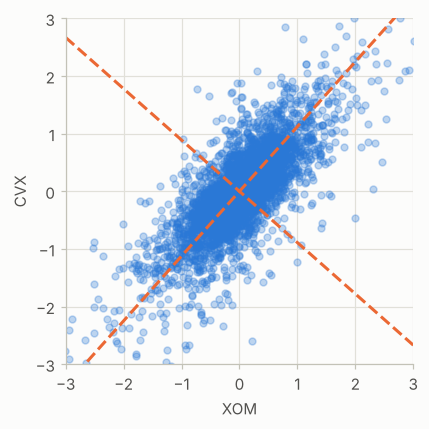

In [5]:
# BOOK CODE (A Simple Example): the principal components as axes of the cloud of points
def abline(slope, intercept, ax):
    """Calculate coordinates of a line based on slope and intercept"""
    x_vals = np.array(ax.get_xlim())
    return (x_vals, intercept + slope * x_vals)

ax = oil_px.plot.scatter(x='XOM', y='CVX', alpha=0.3, figsize=(4, 4))
ax.set_xlim(-3, 3)
ax.set_ylim(-3, 3)
ax.plot(*abline(loadings.loc[0, 'CVX'] / loadings.loc[0, 'XOM'], 0, ax),
        '--', color='C1')
ax.plot(*abline(loadings.loc[1, 'CVX'] / loadings.loc[1, 'XOM'], 0, ax),
        '--', color='C1')

plt.tight_layout()
plt.show()

Interpreting the principal components. The analysis is repeated for 16 stocks since 2011 (four technology, four energy, four finance and four retail stocks), and the screeplot shows the variance of the first ten components.

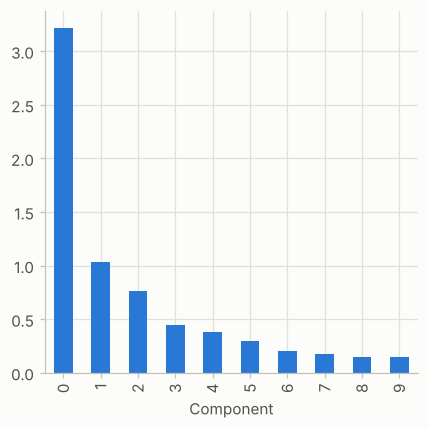

In [6]:
# BOOK CODE (Interpreting principal components): the screeplot
syms = sorted(['AAPL', 'MSFT', 'CSCO', 'INTC', 'CVX', 'XOM', 'SLB', 'COP',
        'JPM', 'WFC', 'USB', 'AXP', 'WMT', 'TGT', 'HD', 'COST'])
top_sp = sp500_px.loc[sp500_px.index >= '2011-01-01', syms]

sp_pca = PCA()
sp_pca.fit(top_sp)

explained_variance = pd.DataFrame(sp_pca.explained_variance_)
ax = explained_variance.head(10).plot.bar(legend=False, figsize=(4, 4))
ax.set_xlabel('Component')

plt.tight_layout()
plt.show()

In [7]:
# NOT IN THE BOOK: the share of the total variance of the first five components, and the cumulative share
print(sp_pca.explained_variance_ratio_[:5].round(3))
print(sp_pca.explained_variance_ratio_[:5].cumsum().round(3))

[0.445 0.143 0.105 0.062 0.053]
[0.445 0.588 0.693 0.755 0.809]


The loadings of the first five components (one row per component, one column per stock), and the bar charts of the book: blue bars are positive loadings, orange bars negative ones.

       AAPL       AXP       COP      COST      CSCO       CVX        HD      INTC       JPM      MSFT       SLB       TGT       USB       WFC       WMT       XOM
0  0.300825  0.246332  0.261529  0.273634  0.064059  0.444490  0.207983  0.076956  0.196397  0.105012  0.481786  0.148833  0.116421  0.145684  0.122304  0.317952
1  0.505116  0.139426 -0.174212  0.416307  0.031939 -0.289373  0.278002  0.033898  0.040723  0.053954 -0.472494  0.228123  0.054796  0.047427  0.222889 -0.154192
2  0.786730 -0.135458  0.002367 -0.465862  0.007524 -0.082374 -0.166320  0.003518 -0.062261 -0.016248  0.194822 -0.160833 -0.048976 -0.041932 -0.175806 -0.090167
3 -0.120586  0.061814 -0.206026  0.092596  0.003904 -0.577665  0.162814 -0.001605  0.057687 -0.012558  0.680914  0.109895  0.016752  0.018614  0.058439 -0.295204
4 -0.111576  0.596666  0.005813 -0.555529  0.039860 -0.109016  0.185488  0.072047  0.385160  0.077135 -0.181332  0.055557  0.155440  0.216425 -0.091541 -0.013277


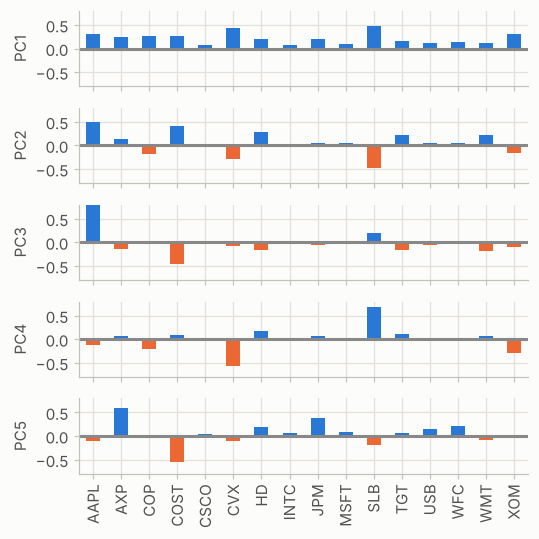

In [8]:
# BOOK CODE (Interpreting principal components): the loadings of the first five components
loadings = pd.DataFrame(sp_pca.components_[0:5, :],
                        columns=top_sp.columns)
print(loadings)

maxPC = 1.01 * loadings.loc[0:5, :].abs().to_numpy().max()

f, axes = plt.subplots(5, 1, figsize=(5, 5), sharex=True)

for i, ax in enumerate(axes):
    pc_loadings = loadings.loc[i, :]
    colors = ['C0' if l > 0 else 'C1' for l in pc_loadings]
    ax.axhline(color='#888888')
    pc_loadings.plot.bar(ax=ax, color=colors)
    ax.set_ylabel(f'PC{i+1}')
    ax.set_ylim(-maxPC, maxPC)

plt.tight_layout()
plt.show()

Correspondence analysis. The table `housetasks.csv` has, for 13 household tasks, the number of households in which the task is done by the wife, alternately, by the husband or jointly. The tasks (rows, blue) and the four columns (orange) are plotted in the plane of the first two dimensions; `adjust_text` moves the labels apart.

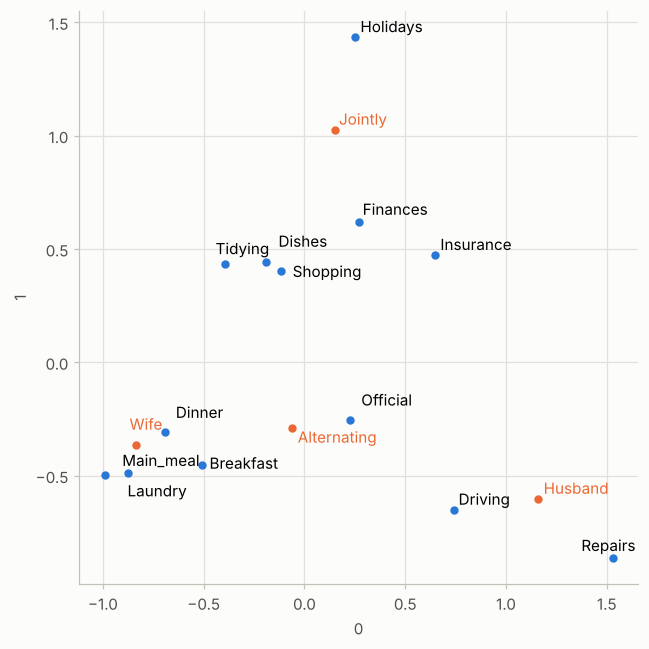

In [9]:
# BOOK CODE (Correspondence analysis): the household tasks
from adjustText import adjust_text

housetasks = pd.read_csv(HOUSE_TASKS_CSV, index_col=0)

ca = prince.CA(n_components=2)
ca = ca.fit(housetasks)

ax = ca.row_coordinates(housetasks).plot.scatter(x=0, y=1, figsize=(6,6))
ca.column_coordinates(housetasks).plot.scatter(x=0, y=1, ax=ax, c='C1')
texts = []
for idx, row in ca.row_coordinates(housetasks).iterrows():
    texts.append(plt.text(row[0], row[1], idx))
for idx, row in ca.column_coordinates(housetasks).iterrows():
    texts.append(plt.text(row[0], row[1], idx, color='C1'))
adjust_text(texts, only_move={'points':'y', 'texts':'y'})
plt.tight_layout()
plt.show()

In [10]:
# NOT IN THE BOOK: the inertia of the two dimensions of the correspondence analysis, and the total inertia
print(ca.eigenvalues_summary)
print(ca.total_inertia_)

          eigenvalue % of variance % of variance (cumulative)
component                                                    
0              0.543        48.69%                     48.69%
1              0.445        39.91%                     88.60%
1.1149404793552338


**Output analysis.**

* **Two stocks.** The daily price changes of `XOM` and `CVX` have a correlation of 0.790. The loadings of the first component are 0.665 and 0.747 and those of the second 0.747 and -0.665: the two components are perpendicular (the second is the first rotated by 90 degrees), and the first, almost the sum of the two stocks, carries 89.6% of the variance of the pair, the second (their difference) 10.4%. In the figure the first dashed line runs along the long axis of the cloud and the second across it.
* **Sixteen stocks, the screeplot.** The variances of the components are about 3.2, 1.0, 0.76, 0.45 and 0.38 for the first five (the total is 7.23): the first component carries 44.5% of the total variance, the first two 58.8%, the first five 80.9%. The curve falls steeply after the first component and then gradually, so there is no sharp elbow; it would be reasonable to keep two to four components.
* **The loadings.** All the loadings of the first component are positive (0.06 for `CSCO` to 0.48 for `SLB`): it is the movement of the market as a whole, felt most by the energy stocks `SLB` (0.48), `CVX` (0.44) and `XOM` (0.32). The second component contrasts `SLB` (-0.47), `CVX` (-0.29), `COP` (-0.17) and `XOM` (-0.15) with `AAPL` (+0.51), `COST` (+0.42), `HD`, `TGT` and `WMT` (0.22 to 0.28): energy against Apple and retail. The third is Apple (+0.79) against Costco (-0.47), the fourth `SLB` (+0.68) against `CVX` (-0.58) and `XOM` (-0.30), the fifth the financial stocks `AXP` (+0.60) and `JPM` (+0.39) against `COST` (-0.56): the later components are contrasts between a few stocks and are harder to interpret. The signs of the bars (blue positive, orange negative) could all be flipped for a component without changing its meaning.
* **Correspondence analysis.** The first two dimensions carry 48.7% and 39.9% of the inertia, 88.6% together; the total inertia is 1.115, which is the chi-square statistic of independence of the table (1,944) divided by its total count (1,744). In the plot the first dimension separates the tasks done by the wife (`Laundry`, `Main_meal`, `Dinner`, `Breakfast`, on the left, near the point `Wife`) from those done by the husband (`Repairs`, `Driving`, `Insurance`, on the right, near `Husband`). The second dimension separates the tasks done jointly (`Holidays`, `Finances`, at the top, near `Jointly`) from the rest; `Tidying`, `Dishes` and `Shopping` lie between `Wife` and `Jointly`, and `Official` is closest to `Alternating`. As the rows and the columns share the same plane, a task and the person it goes with lie in the same direction from the centre (the distance between a row point and a column point is not meaningful in itself, only the directions and the distances among the rows, or among the columns).

---
## 2. K-means clustering

*Book section: "K-Means Clustering" (a simple example, the K-means algorithm, interpreting the clusters, selecting the number of clusters). The code of the script clusters the days of two stocks and of sixteen stocks.*

### Summary

* **Clustering** divides the records into groups such that the records of a group are similar to each other and different from those of the other groups. It is used to explore data, to find segments (of customers, of days...), and to create a categorical variable for later models. **K-means** is the oldest and most used method: the analyst chooses the number of clusters $K$, and each cluster is represented by its **centre** (the mean of its records, the "centroid"). The method looks for the division that makes the records as close as possible to the centre of their own cluster, in terms of the **within-cluster sum of squares**.
* **A simple example.** The daily price changes of `XOM` and `CVX` since 2011 are divided into four clusters. The table of centres has one row per cluster; the figure colours the days by cluster, with the centres in black: the centres lie along the diagonal of the plot, from the days with a strong fall of both stocks to the days with a strong rise of both: the two stocks usually move in the same direction.
* **The algorithm.** (1) Choose $K$ initial centres. (2) Assign every record to the nearest centre. (3) Replace each centre by the mean of the records assigned to it. (4) Repeat (2) and (3) until the assignments no longer change. The result depends on the initial centres, and the algorithm can stop in a local optimum, so scikit-learn repeats it from several starting points (`n_init`; `'auto'` is 1 run with the default smart initialization, `k-means++`) and keeps the best. `max_iter` limits the iterations of each run.
* **Interpreting the clusters.** The sizes of the clusters and their centres are the first things to look at. In the example, 16 stocks from 2011 on are divided into five clusters; the bar charts of the centres show in which stocks each cluster is high or low (blue bars above zero, orange bars below). The numbering of the clusters is arbitrary and changes from run to run, only the content of a cluster is meaningful.
* **Selecting the number of clusters.** There is no single right $K$. The **elbow method** plots a measure of the within-cluster variation against $K$ and looks for the point after which more clusters bring little improvement. The measure falls with every added cluster, so the curve has no minimum; the elbow is a judgement. The script plots the within-cluster sum of squares divided by the number of clusters, for $K = 2, \dots, 14$.

### Theory

**The objective.** For the clusters $C_1, \dots, C_K$ with centres $\mu_1, \dots, \mu_K$, K-means minimizes the within-cluster sum of squares (the **inertia** of scikit-learn)
$$W = \sum_{k=1}^K \sum_{i \in C_k} \lVert x_i - \mu_k \rVert^2 .$$
The total sum of squares around the overall mean splits as $T = W + B$, with $B = \sum_k |C_k|\,\lVert\mu_k - \bar x\rVert^2$ the between-cluster part, so minimizing $W$ maximizes $B$.

**Lloyd's algorithm.** Assigning each record to its nearest centre cannot increase $W$ for fixed centres, and replacing the centres by the cluster means cannot increase it for fixed assignments (the mean minimizes the sum of squared distances). $W$ therefore decreases at each step and, as the number of assignments is finite, the algorithm stops, but only at a local minimum. **k-means++** chooses the initial centres at random with a probability proportional to the squared distance to the nearest centre already chosen, which spreads them out.

**Properties.** K-means uses the Euclidean distance, so the variables need comparable scales (section 5), and it favours compact, roughly spherical clusters of similar size. The within-cluster sum of squares $W_K$ is non-increasing in $K$ ($W_K = 0$ for $K = n$), which is why a criterion such as the elbow, and not the minimum, is needed.

### Book code

A simple example. The seed in the first line is not in the book: the script does not fix the random numbers of the initialization, so the numbering of the clusters would change from run to run.

In [11]:
# BOOK CODE (A Simple Example): four clusters of the price changes of two stocks
np.random.seed(1)  # NOT IN THE BOOK: the initial centres are random and the script has no seed

df = sp500_px.loc[sp500_px.index >= '2011-01-01', ['XOM', 'CVX']]
kmeans = KMeans(n_clusters=4, n_init='auto').fit(df)
df['cluster'] = kmeans.labels_
print(df.head())

centers = pd.DataFrame(kmeans.cluster_centers_, columns=['XOM', 'CVX'])
print(centers)

                 XOM       CVX  cluster
2011-01-03  0.736805  0.240681        3
2011-01-04  0.168668 -0.584516        0
2011-01-05  0.026631  0.446985        3
2011-01-06  0.248558 -0.919751        0
2011-01-07  0.337329  0.180511        3
        XOM       CVX
0 -0.286422 -0.492965
1  1.092072  1.581077
2 -1.123045 -1.718845
3  0.325846  0.449970


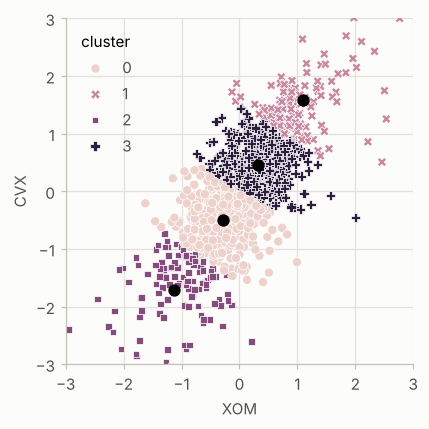

In [12]:
# BOOK CODE (A Simple Example): the clusters and their centres
fig, ax = plt.subplots(figsize=(4, 4))
ax = sns.scatterplot(x='XOM', y='CVX', hue='cluster', style='cluster',
                     ax=ax, data=df)
ax.set_xlim(-3, 3)
ax.set_ylim(-3, 3)
centers.plot.scatter(x='XOM', y='CVX', ax=ax, s=50, color='black')

plt.tight_layout()
plt.show()

The K-means algorithm with 16 stocks and five clusters (the comment of the script explains `n_init` and `max_iter`). The seed is again not in the book.

In [13]:
# BOOK CODE (K-Means Algorithm): five clusters of sixteen stocks
# The _scikit-learn_ algorithm is repeated 10 times by default (`n_init`), `max_iter` is used to control the number of iterations.
np.random.seed(1)  # NOT IN THE BOOK: the initial centres are random and the script has no seed

syms = sorted(['AAPL', 'MSFT', 'CSCO', 'INTC', 'CVX', 'XOM', 'SLB', 'COP',
               'JPM', 'WFC', 'USB', 'AXP', 'WMT', 'TGT', 'HD', 'COST'])
top_sp = sp500_px.loc[sp500_px.index >= '2011-01-01', syms]
kmeans = KMeans(n_clusters=5, n_init='auto').fit(top_sp)

Interpreting the clusters: the number of days in each cluster and the centre of each cluster (blue bars are stocks with a positive mean price change in the cluster, orange bars negative).

Counter({np.int32(4): 322, np.int32(1): 271, np.int32(0): 256, np.int32(3): 152, np.int32(2): 130})


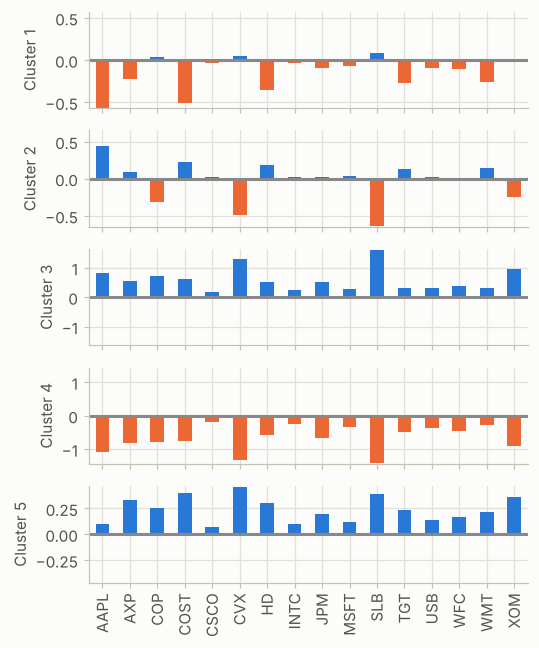

In [14]:
# BOOK CODE (Interpreting the Clusters): sizes and centres of the clusters
from collections import Counter
print(Counter(kmeans.labels_))

centers = pd.DataFrame(kmeans.cluster_centers_, columns=syms)

f, axes = plt.subplots(5, 1, figsize=(5, 6), sharex=True)
for i, ax in enumerate(axes):
    center = centers.loc[i, :]
    maxPC = 1.01 * np.max(np.max(np.abs(center)))
    colors = ['C0' if l > 0 else 'C1' for l in center]
    ax.axhline(color='#888888')
    center.plot.bar(ax=ax, color=colors)
    ax.set_ylabel(f'Cluster {i + 1}')
    ax.set_ylim(-maxPC, maxPC)

plt.tight_layout()
plt.show()

In [15]:
# NOT IN THE BOOK: the centres of the five clusters as numbers (the bars above show them)
print(centers.round(2))

   AAPL   AXP   COP  COST  CSCO   CVX    HD  INTC   JPM  MSFT   SLB   TGT   USB   WFC   WMT   XOM
0 -0.57 -0.22  0.04 -0.51 -0.04  0.05 -0.35 -0.04 -0.09 -0.07  0.08 -0.27 -0.10 -0.10 -0.26 -0.01
1  0.45  0.08 -0.31  0.23  0.02 -0.49  0.18  0.03  0.02  0.04 -0.64  0.13  0.03  0.01  0.14 -0.25
2  0.81  0.55  0.73  0.61  0.17  1.30  0.53  0.23  0.52  0.28  1.62  0.31  0.32  0.39  0.31  0.97
3 -1.08 -0.83 -0.79 -0.77 -0.20 -1.33 -0.58 -0.24 -0.66 -0.33 -1.43 -0.48 -0.35 -0.46 -0.28 -0.92
4  0.10  0.34  0.26  0.40  0.07  0.46  0.30  0.10  0.20  0.12  0.39  0.24  0.13  0.17  0.22  0.36


Selecting the number of clusters: K-means is run for $K = 2, \dots, 14$ (with `random_state=0` in the script itself) and the average within-cluster sum of squares is plotted.

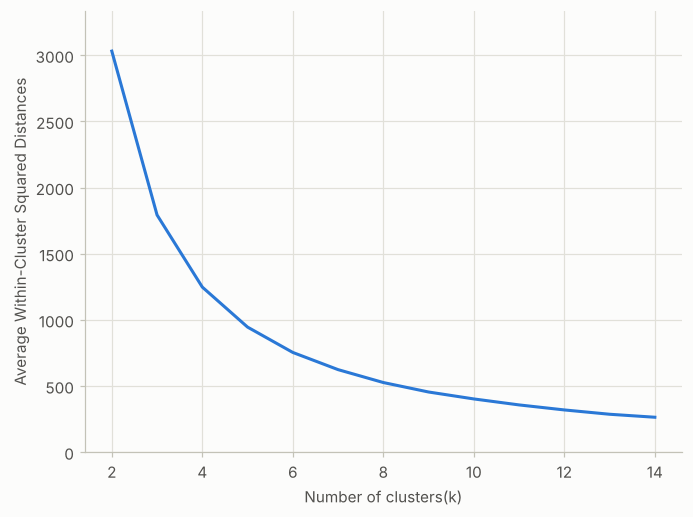

In [16]:
# BOOK CODE (Selecting the Number of Clusters): the elbow plot
inertia = []
for n_clusters in range(2, 15):
    kmeans = KMeans(n_clusters=n_clusters, random_state=0, n_init='auto').fit(top_sp)
    inertia.append(kmeans.inertia_ / n_clusters)
inertias = pd.DataFrame({'n_clusters': range(2, 15), 'inertia': inertia})
ax = inertias.plot(x='n_clusters', y='inertia')
plt.xlabel('Number of clusters(k)')
plt.ylabel('Average Within-Cluster Squared Distances')
plt.ylim((0, 1.1 * inertias.inertia.max()))
ax.legend().set_visible(False)

plt.tight_layout()
plt.show()

In [17]:
# NOT IN THE BOOK: the values of the elbow plot
print(inertias.round(1).to_string(index=False))

 n_clusters  inertia
          2   3031.8
          3   1793.2
          4   1248.1
          5    945.7
          6    754.1
          7    624.3
          8    526.8
          9    455.2
         10    402.8
         11    357.6
         12    319.6
         13    287.0
         14    264.4


**Output analysis.**

* **Two stocks, four clusters.** The four centres, from the days when both stocks fell most to those when they rose most, are (-1.12, -1.72), (-0.29, -0.49), (0.33, 0.45) and (1.09, 1.58) for `XOM` and `CVX`: they lie along the diagonal, with the `CVX` coordinate about 1.4 to 1.7 times the `XOM` one. The figure shows the four regions of the cloud (the markers and colours distinguish the clusters; the cluster numbers 0 to 3 are arbitrary). The first rows of the table are the days from 2011-01-03 on, with their cluster.
* **Sixteen stocks, five clusters.** The cluster sizes are 322, 271, 256, 152 and 130 days (1,131 in all; the keys of the `Counter` are shown as `np.int32(...)` by `numpy` 2, and the clusters are numbered from 0 in the code and from 1 in the bar charts). From the centres: cluster 3 (130 days) is a day of strong rises of all stocks, led by `SLB` (+1.62), `CVX` (+1.30) and `XOM` (+0.97); cluster 4 (152 days) is the mirror image, strong falls (`SLB` -1.43, `CVX` -1.33, `AAPL` -1.08); cluster 5, the largest (322 days), has small positive changes for all stocks (0.07 to 0.46). The other two clusters are specific: cluster 2 (271 days) has the energy stocks down (`SLB` -0.64, `CVX` -0.49) with Apple and retail up (`AAPL` +0.45, `COST` +0.23), and cluster 1 (256 days) has Apple and retail down (`AAPL` -0.57, `COST` -0.51, `HD` -0.35) with the energy stocks about unchanged. These are the same patterns as the first two principal components of section 1.
* **The number of clusters.** The average within-cluster sum of squares falls from 3,032 for 2 clusters to 1,793 for 3, 1,248 for 4, 946 for 5, 754 for 6 and 624 for 7, and then more slowly to 264 for 14 clusters; each step is 41%, 30%, 24%, 20% and 17% smaller than the last one. The curve bends gradually and has no clear elbow, so the choice of 5 clusters in the example is a judgement.

---
## 3. Hierarchical clustering

*Book section: "Hierarchical Clustering" (a simple example, the dendrogram, the agglomerative algorithm, measures of dissimilarity). The code of the script clusters 18 stocks and compares four measures of dissimilarity on the days of two stocks.*

### Summary

* **Hierarchical clustering** does not need the number of clusters in advance. It builds a whole **hierarchy** of nested clusters, from which any number of clusters can be read afterwards. It is flexible, it can be applied to many kinds of data and distances, and it makes it easy to see the structure of small data sets; it does not scale to very large ones (it needs the distances between all pairs of records).
* **The agglomerative algorithm** works from the bottom up: (1) every record starts as a cluster of its own; (2) the two **closest** clusters are merged; (3) step 2 is repeated until one cluster with all the records is left. For $n$ records there are $n - 1$ merges. What "closest" means for clusters with several records is the **measure of dissimilarity** (the linkage), see below.
* **A simple example.** The *stocks* are the records here: the table is transposed, so each of the 18 rows is a stock and each column a day since 2011. `linkage` returns the merges as a matrix with one row per merge, 17 rows with 4 columns: the two clusters merged, the distance between them and the size of the new cluster.
* **The dendrogram** draws the merges as a tree: the leaves are the records, each junction is a merge, and its height is the distance at which the clusters were merged. The branches that are joined at a low height are similar to each other. Cutting the tree at a height gives the clusters below it; `fcluster(Z, 4, criterion='maxclust')` finds the cut that gives four clusters. In the example the four clusters are the four energy stocks, a large group of 12 other stocks, and Amazon and Google alone; these two have by far the largest price changes, and the prices are not standardized before the distances are computed (section 5).
* **Measures of dissimilarity.** The distance between two clusters $A$ and $B$ can be defined as the smallest distance between a record of $A$ and one of $B$ (**single linkage**), the largest (**complete linkage**), the average of all the pairs (**average linkage**), or by the increase of the within-cluster sum of squares caused by the merge (**minimum variance**, **Ward's method**). The choice changes the clusters: single linkage tends to chain records together and to produce one very large cluster and several small ones; complete linkage and Ward's method tend to give compact clusters of more similar size; average linkage is in between. The figure compares the four methods on the price changes of `XOM` and `CVX`, cut at four clusters.

### Theory

**Linkage.** With $d(a, b)$ the distance between two records, the distance between clusters is
$$d_{\text{single}}(A, B) = \min_{a \in A,\, b \in B} d(a, b), \qquad d_{\text{complete}}(A, B) = \max_{a \in A,\, b \in B} d(a, b), \qquad d_{\text{average}}(A, B) = \frac{1}{|A||B|}\sum_{a \in A}\sum_{b \in B} d(a, b).$$
**Ward's method** merges the pair of clusters for which the increase of the total within-cluster sum of squares is smallest. This increase is $\Delta(A, B) = \dfrac{|A||B|}{|A| + |B|}\,\lVert \bar x_A - \bar x_B \rVert^2$, so it penalizes the merging of large clusters and of clusters with distant centres.

**The matrix `Z`.** Row $i$ of `Z` describes the merge number $i$, which creates the cluster with the index $n + i$: the indices of the two clusters merged, their distance (non-decreasing from row to row for these four linkages) and the number of records of the new cluster. The dendrogram is a drawing of this matrix.

**Cost.** The algorithm needs the $n \times n$ matrix of distances, so memory grows with $n^2$ and time at least as fast; for large $n$ K-means or model-based clustering on a sample are used instead.

### Book code

A simple example. The 18 stocks are the rows of the table (`transpose`), and the clustering uses complete linkage. The cell prints the shape of the matrix of merges.

In [18]:
# BOOK CODE (A Simple Example): complete linkage on 18 stocks
syms1 = ['AAPL', 'AMZN', 'AXP', 'COP', 'COST', 'CSCO', 'CVX', 'GOOGL', 'HD',
         'INTC', 'JPM', 'MSFT', 'SLB', 'TGT', 'USB', 'WFC', 'WMT', 'XOM']
df = sp500_px.loc[sp500_px.index >= '2011-01-01', syms1].transpose()

Z = linkage(df, method='complete')
print(Z.shape)

(17, 4)


The dendrogram, and the clusters obtained by cutting the tree at four clusters.

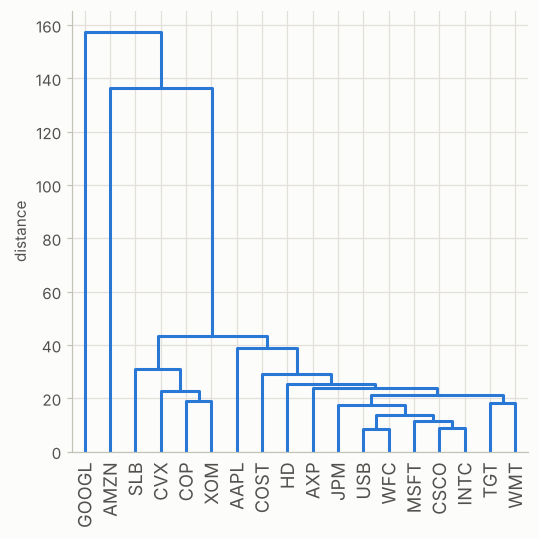

1 : COP, CVX, SLB, XOM
2 : AAPL, AXP, COST, CSCO, HD, INTC, JPM, MSFT, TGT, USB, WFC, WMT
3 : AMZN
4 : GOOGL


In [19]:
# BOOK CODE (The Dendrogram): the tree and the four clusters
fig, ax = plt.subplots(figsize=(5, 5))
dendrogram(Z, labels=list(df.index), color_threshold=0)
plt.xticks(rotation=90)
ax.set_ylabel('distance')

plt.tight_layout()
plt.show()

memb = fcluster(Z, 4, criterion='maxclust')
memb = pd.Series(memb, index=df.index)
for key, item in memb.groupby(memb):
    print(f"{key} : {', '.join(item.index)}")

Measures of dissimilarity. For each of the four methods the days of `XOM` and `CVX` are divided into four clusters and coloured by cluster (the colours of the clusters differ from panel to panel).

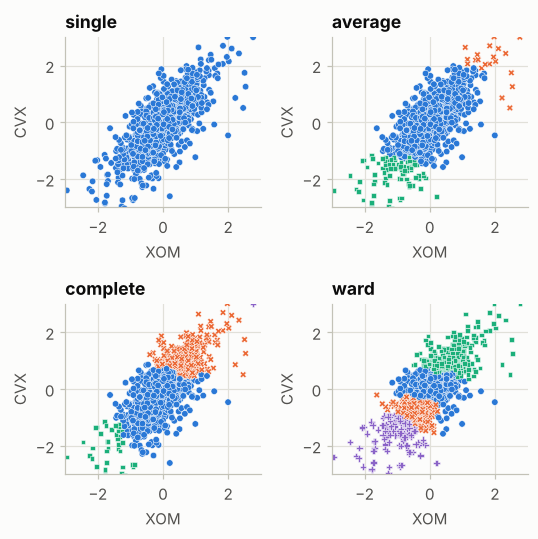

In [20]:
# BOOK CODE (Measures of Dissimilarity): single, average, complete and Ward linkage
df = sp500_px.loc[sp500_px.index >= '2011-01-01', ['XOM', 'CVX']]
fig, axes = plt.subplots(nrows=2, ncols=2, figsize=(5, 5))
for i, method in enumerate(['single', 'average', 'complete', 'ward']):
    ax = axes[i // 2, i % 2]
    Z = linkage(df, method=method)
    colors = [f'C{c+1}' for c in fcluster(Z, 4, criterion='maxclust')]
    ax = sns.scatterplot(x='XOM', y='CVX', hue=colors, style=colors,
                         size=0.5, ax=ax, data=df, legend=False)

    ax.set_xlim(-3, 3)
    ax.set_ylim(-3, 3)
    ax.set_title(method)

plt.tight_layout()
plt.show()

In [21]:
# NOT IN THE BOOK: the sizes of the four clusters of each method
for method in ['single', 'average', 'complete', 'ward']:
    sizes = sorted(Counter(fcluster(linkage(df, method=method), 4, criterion='maxclust')).values(), reverse=True)
    print(f'{method:9s}', sizes)

single    [1127, 2, 1, 1]
average   [1015, 91, 24, 1]
complete  [805, 277, 44, 5]
ward      [464, 290, 254, 123]


**Output analysis.**

* **The matrix of merges** has the shape (17, 4): 17 merges for 18 stocks.
* **The dendrogram** shows the structure at once: the energy stocks `COP`, `CVX`, `SLB` and `XOM` form a group that is merged early (distances up to about 31), the 12 other stocks form a second group (their last merge is at about 39) which joins the energy group at 43, and the two leftover stocks, `AMZN` and `GOOGL`, join the rest only at the distances of 136 and 157. These two have by far the largest price changes, and the distances are computed from the unstandardized values. Cutting at four clusters gives exactly the groups printed: 1: `COP`, `CVX`, `SLB`, `XOM`; 2: the 12 other stocks; 3: `AMZN`; 4: `GOOGL`.
* **The four measures of dissimilarity** give very different clusters for the same 1,131 days (the sizes of the four clusters are in the cell after the figure). With single linkage 1,127 days form one cluster and the other three clusters have 2, 1 and 1 days (isolated days far from the others): the chaining effect. Average linkage gives 1,015, 91, 24 and 1 days, complete linkage 805, 277, 44 and 5, and Ward's method 464, 290, 254 and 123: only Ward's method divides the days into groups of comparable size, with compact regions in the plane (low, medium and high changes of the two stocks).

---
## 4. Model-based clustering

*Book section: "Model-Based Clustering" (multivariate normal distribution, mixtures of normals, selecting the number of clusters). The code of the script draws a bivariate normal distribution, fits a mixture of two normals to the days of two stocks and compares mixtures by BIC.*

### Summary

* **Model-based clustering** replaces the geometric idea of the methods above (distance to a centre or to another cluster) by a statistical model: the data are assumed to come from a **mixture** of several populations, each of them a **multivariate normal distribution** with its own mean vector and covariance matrix. Fitting the model estimates these, and also the share of the data that comes from each population. A record is then assigned to the population from which it most probably comes, and the probabilities are available too (a "soft" assignment, where K-means has only a "hard" one).
* **The multivariate normal distribution** generalizes the normal distribution to several variables: it is defined by the vector of means and the **covariance matrix** (the variances and the covariances of the variables). In two variables the lines of equal density are ellipses centred at the mean, with a shape and a tilt given by the covariances. The figure of the script has a mean of $(0.5, -0.5)$ and the covariance matrix $\begin{pmatrix}1 & 1\\1 & 2\end{pmatrix}$, with black contours that contain 50%, 75%, 95% and 99% of the probability.
* **Mixtures of normals.** A model with two components is fitted to the price changes of `XOM` and `CVX` since 2011 with `GaussianMixture(n_components=2)`. The fit estimates the means and the covariance matrices of the components; the two components have almost the same centre, but one is a narrow cloud (days of small changes) and the other a wide one (days of large changes). The fit is by the **EM algorithm**, which alternates between computing the probability of each record for each component (E step) and updating the parameters with these probabilities as weights (M step); it can stop in a local maximum, hence the dependence on the starting values.
* **Selecting the number of clusters.** Adding components always increases the likelihood, so a criterion that penalizes the number of parameters is needed: the **BIC** (Bayesian information criterion). In scikit-learn, **a lower BIC is better**. The script computes the BIC for 1 to 8 components and for four structures of the covariance matrices (`full`: each component its own matrix; `tied`: one matrix for all; `diag`: diagonal matrices; `spherical`: one variance per component) and plots the curves; the best model is the one with the lowest BIC.

### Theory

**The multivariate normal density.** For $x \in \mathbb R^p$ with mean $\mu$ and covariance matrix $\Sigma$,
$$\varphi(x \mid \mu, \Sigma) = \frac{1}{(2\pi)^{p/2}\,|\Sigma|^{1/2}}\exp\Bigl(-\tfrac12 (x - \mu)^\top \Sigma^{-1}(x - \mu)\Bigr).$$
The quantity $(x - \mu)^\top\Sigma^{-1}(x - \mu)$ is the squared Mahalanobis distance, which follows a chi-square distribution with $p$ degrees of freedom. For $p = 2$ the ellipse that contains the probability $q$ is therefore the contour with density $(1 - q)/(2\pi|\Sigma|^{1/2})$; this is the function `probLevel` of the script, in which $|\Sigma|^{1/2} = (1 \cdot 2 - 1 \cdot 1)^{1/2} = 1$ (the constant `D = 1`).

**The mixture.** The density is $f(x) = \sum_{k=1}^K \pi_k\,\varphi(x \mid \mu_k, \Sigma_k)$ with weights $\pi_k \ge 0$ that sum to 1. The **EM algorithm** maximizes the likelihood by iterating
$$\text{E step:}\quad \gamma_{ik} = \frac{\pi_k\,\varphi(x_i \mid \mu_k, \Sigma_k)}{\sum_{j}\pi_j\,\varphi(x_i \mid \mu_j, \Sigma_j)}, \qquad \text{M step:}\quad N_k = \sum_i \gamma_{ik},\;\; \pi_k = \frac{N_k}{n},\;\; \mu_k = \frac{1}{N_k}\sum_i\gamma_{ik}x_i,\;\; \Sigma_k = \frac{1}{N_k}\sum_i\gamma_{ik}(x_i - \mu_k)(x_i - \mu_k)^\top .$$
The likelihood does not decrease at any iteration. The numbers $\gamma_{ik}$ are the probabilities of membership; `predict` assigns each record to the component with the largest one.

**BIC.** $\text{BIC} = -2\ln\hat L + m\ln n$, where $\hat L$ is the maximized likelihood, $m$ the number of free parameters and $n$ the number of records; scikit-learn minimizes it. For $p = 2$ the parameters are $K - 1$ weights, $2K$ means and the covariance parameters: $3K$ for `full`, $3$ for `tied`, $2K$ for `diag` and $K$ for `spherical`.

### Book code

The bivariate normal distribution of the example. The filled contours show the density, the black lines enclose 50%, 75%, 95% and 99% of the probability, and the black dot is the mean.

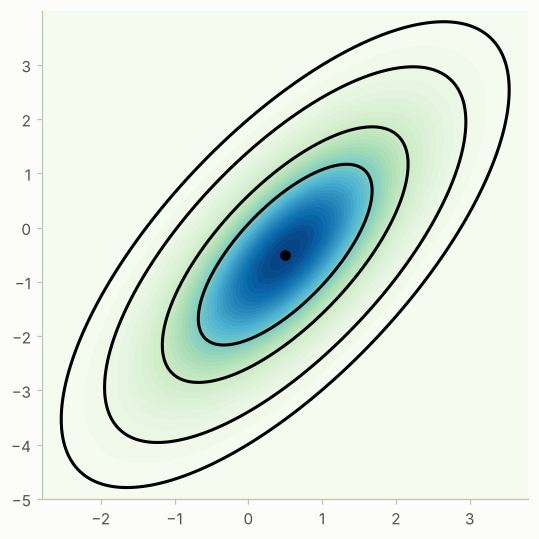

In [22]:
# BOOK CODE (Multivariate Normal Distribution): density of a bivariate normal distribution
# Define a colormap that corresponds to the probability levels

mean = [0.5, -0.5]
cov = [[1, 1], [1, 2]]
probability = [.5, .75, .95, .99]
def probLevel(p):
    D = 1
    return (1 - p) / (2 * math.pi * D)
levels = [probLevel(p) for p in probability]

fig, ax = plt.subplots(figsize=(5, 5))

x, y = np.mgrid[-2.8:3.8:.01, -5:4:.01]
pos = np.empty(x.shape + (2,))
pos[:, :, 0] = x; pos[:, :, 1] = y
rv = multivariate_normal(mean, cov)


CS = ax.contourf(x, y, rv.pdf(pos), cmap=cm.GnBu, levels=50)
ax.contour(CS, levels=levels, colors=['black'])
ax.plot(*mean, color='black', marker='o')


plt.tight_layout()
plt.show()

Mixtures of normals. A mixture of two normal distributions is fitted to the price changes of `XOM` and `CVX`; the cell prints the BIC, plots the days coloured by the component they are assigned to, and prints the means and the covariance matrices of the components. The seed is not in the book (the starting values of the EM algorithm are random).

4589.92885731864


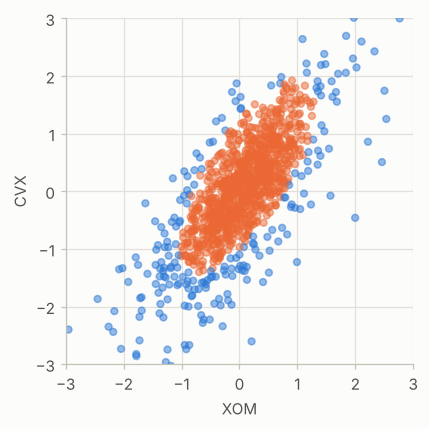

Mean
[[-0.05031426 -0.21161823]
 [ 0.07246995  0.10494619]]
Covariances
[[[0.97123064 0.97764343]
  [0.97764343 1.67233845]]

 [[0.26822676 0.27562091]
  [0.27562091 0.51679853]]]


In [23]:
# BOOK CODE (Mixtures of Normals): two components for the price changes of two stocks
np.random.seed(1)  # NOT IN THE BOOK: the starting values of the EM algorithm are random and the script has no seed

df = sp500_px.loc[sp500_px.index >= '2011-01-01', ['XOM', 'CVX']]
mclust = GaussianMixture(n_components=2).fit(df)
print(mclust.bic(df))

fig, ax = plt.subplots(figsize=(4, 4))
colors = [f'C{c}' for c in mclust.predict(df)]
df.plot.scatter(x='XOM', y='CVX', c=colors, alpha=0.5, ax=ax)
ax.set_xlim(-3, 3)
ax.set_ylim(-3, 3)

plt.tight_layout()
plt.show()

print('Mean')
print(mclust.means_)
print('Covariances')
print(mclust.covariances_)

In [24]:
# NOT IN THE BOOK: the weights of the two components, and the number of days assigned to each
print(mclust.weights_)
print(np.bincount(mclust.predict(df)))

[0.34507118 0.65492882]
[215 916]


Selecting the number of clusters: BIC for 1 to 8 components and the four types of covariance matrix. Lower is better. The seed is not in the book.

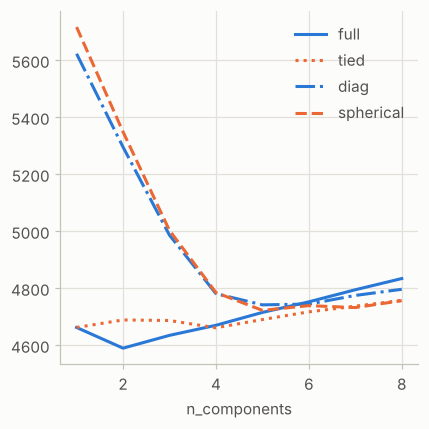

In [25]:
# BOOK CODE (Selecting the number of clusters): BIC of the mixtures
np.random.seed(1)  # NOT IN THE BOOK: the starting values of the EM algorithm are random and the script has no seed

results = []
covariance_types = ['full', 'tied', 'diag', 'spherical']
for n_components in range(1, 9):
    for covariance_type in covariance_types:
        mclust = GaussianMixture(n_components = n_components, warm_start=True,
                                 covariance_type = covariance_type)
        mclust.fit(df)
        results.append({
            'bic': mclust.bic(df),
            'n_components': n_components,
            'covariance_type': covariance_type,
        })

results = pd.DataFrame(results)

colors = ['C0', 'C1', 'C2', 'C3']
styles = ['C0-','C1:','C0-.', 'C1--']

fig, ax = plt.subplots(figsize=(4, 4))
for i, covariance_type in enumerate(covariance_types):
    subset = results.loc[results.covariance_type == covariance_type, :]
    subset.plot(x='n_components', y='bic', ax=ax, label=covariance_type,
                kind='line', style=styles[i]) # , color=colors[i])

plt.tight_layout()
plt.show()

In [26]:
# NOT IN THE BOOK: the BIC values of the plot
print(results.pivot(index='n_components', columns='covariance_type', values='bic').round(1))

covariance_type    diag    full  spherical    tied
n_components                                      
1                5623.0  4662.5     5716.7  4662.5
2                5295.7  4589.8     5349.1  4688.9
3                4986.3  4634.8     5003.0  4686.9
4                4781.2  4670.1     4784.9  4661.3
5                4741.8  4715.2     4722.6  4690.3
6                4744.5  4752.4     4739.1  4717.3
7                4774.9  4794.8     4732.3  4737.1
8                4796.4  4834.1     4756.6  4757.5


**Output analysis.**

* **The bivariate normal distribution.** The density is highest at the mean (the black dot) and the contours are tilted ellipses: the variables are positively correlated (covariance 1, with variances 1 and 2, a correlation of $1/\sqrt{2} \approx 0.71$). The four black ellipses enclose 50%, 75%, 95% and 99% of the probability.
* **The mixture of two normals** has a BIC of 4,589.9 and separates the 1,131 days into 916 days of the narrow component (the orange points in the centre of the cloud) and 215 days of the wide one (the blue points around it, mostly the days of large changes). The means are close, (0.072, 0.105) for the narrow and (-0.050, -0.212) for the wide component, but the covariances differ: the narrow component has variances of 0.268 for `XOM` and 0.517 for `CVX` (standard deviations 0.52 and 0.72), the wide one 0.971 and 1.672 (0.99 and 1.29), and the correlation is about 0.74 and 0.77. The estimated weights are 0.655 and 0.345; the wide component has 34.5% of the weight but receives only 19% of the days when each day is assigned to its most probable component, because over the middle of the cloud the narrow component has the higher density. In short: days of small and days of large changes, as in a mixture of a calm and a turbulent market.
* **The number of components.** The lowest BIC of all 32 combinations, 4,589.8, is for 2 components with `full` covariance matrices. The next ones are `tied` with 4 components (4,661.3) and `full` with 1 component (4,662.5), about 72 points higher. The BIC of the `full` model rises again from 3 components on (4,634.8, 4,670.1, 4,715.2, ...) as the extra parameters are not worth the small gain of the likelihood. The `diag` and `spherical` models, which cannot represent the correlation of the two stocks, need 5 or more components to get close (4,741.8 and 4,722.6 for 5 components) and never reach the 2-component `full` model. So the data favour two components with their own covariance matrices.

---
## 5. Scaling and categorical variables

*Book section: "Scaling and Categorical Variables" (scaling the variables, dominant variables, categorical data and Gower's distance, problems in clustering with mixed data types). The code of the script clusters the defaulted loans with and without scaling, shows the dominance of two stocks in a PCA, and clusters mixed data.*

### Summary

* **Why scale.** PCA, K-means and hierarchical clustering are all based on distances (or on variances), which depend on the units of the variables: a variable measured in dollars counts much more than one measured in per cent. The remedy is to **standardize** the variables, that is to subtract the mean and divide by the standard deviation, so that every variable has a mean of 0 and a standard deviation of 1 (z-score); other scalings, for instance to the range from 0 to 1, are possible.
* **Scaling the variables: an example.** The 22,671 loans in default are clustered in four groups using six variables (the amount of the loan, the annual income, the revolving balance, the number of open accounts, the debt-to-income ratio and the revolving utilization). Without scaling, the clusters are determined almost only by the three variables with the largest numbers, the income, the balance and the loan amount: the table of centres has one cluster with 88 loans with an average income of about 410,000 dollars, and the other variables hardly differ between clusters. With standardized variables the four clusters have more even sizes and also differ in the debt-to-income ratio and in the utilization of the revolving credit. The centres are given in the original units (`inverse_transform`).
* **Dominant variables.** Even when the variables are in the same units, a variable with a much larger variance dominates. The example is a PCA on 18 stocks since 2005 that include Google and Amazon, whose price changes are much larger than those of the other stocks (standard deviations of 4.2 and 3.0, against 1.3 or less for the others). Without scaling, the first component is practically `GOOGL` (loading 0.857) with some `AMZN`, and the second is `AMZN` with the opposite sign for `GOOGL`; the other 16 stocks have loadings below 0.12. The PCA describes two stocks, not the structure of the market. Standardizing the variables, or leaving the dominant ones out, would reveal the structure of the others.
* **Categorical data and Gower's distance.** Distance-based methods need numbers, so categorical variables must be converted. One way is to use dummy variables (0 and 1), but then the binary variables dominate or are not comparable with the numeric ones. **Gower's distance** handles variables of mixed types: for every variable it computes a dissimilarity between two records between 0 and 1 (the absolute difference divided by the range for a numeric variable, 0 or 1 for a categorical one, depending on whether the values are equal) and averages them. The script has no Python implementation (it only lists five loans and notes that the R function `daisy` does this; the R code is in the script as comments, and is not reproduced here), and the figure of the book comes from R.
* **Problems in clustering with mixed data.** The example clusters the defaulted loans with four variables, two numeric (`dti`, `payment_inc_ratio`) and two categorical (`home_`, `pub_rec_zero`), the latter converted to dummy variables and then standardized. In the centres the dummy variables are practically 0 or 1 within a cluster: the clusters are defined by the combinations of the categorical variables, and the numeric variables play a smaller part. The standardization has given each 0-1 variable the same weight as a continuous variable, but a variable with two values cannot be "close": it contributes a large jump to the distance whenever the categories differ.

### Theory

**Standardization.** The z-score of $x_{ij}$ is $z_{ij} = (x_{ij} - \bar x_j)/s_j$. In the squared Euclidean distance $\sum_j (x_{ij} - x_{kj})^2$ a variable $j$ contributes in proportion to the square of its scale, so a variable with a standard deviation 100 times larger contributes $10^4$ times more. After standardization all variables have variance 1 (and PCA of the standardized variables is PCA of the correlation matrix, whose total variance is the number of variables $p$).

**Gower's distance.** For two records $i$ and $k$ and variables $j = 1, \dots, p$, the dissimilarity is
$$d_{ik} = \frac{1}{p}\sum_{j=1}^p d_{ik}^{(j)}, \qquad d_{ik}^{(j)} = \begin{cases}\dfrac{|x_{ij} - x_{kj}|}{R_j} & \text{numeric variable, } R_j = \text{range of the variable,}\\[2mm] \mathbf 1\{x_{ij} \ne x_{kj}\} & \text{categorical variable.}\end{cases}$$
(Gower's similarity coefficient also allows for missing values, by averaging over the variables that are known for both records, and for weights per variable.) The resulting matrix of dissimilarities can be used by hierarchical clustering.

**One-hot encoding and distance.** A categorical variable with $L$ levels becomes $L$ dummy variables (or $L - 1$); two records that differ in the category differ in two dummy variables, so their squared Euclidean distance in this variable is 2 (before standardization), against 0 when they agree. A rare category has a small standard deviation, so after standardization its dummy variable gets a large scale.

### Book code

Scaling the variables. The loans in default are clustered in four groups with the six numeric variables, first as they are and then standardized with `StandardScaler`. Each table has the centre of each cluster (in the original units) and its size.

In [27]:
# BOOK CODE (Scaling the Variables): K-means on the defaulted loans, unscaled and scaled
from collections import Counter

loan_data = pd.read_csv(LOAN_DATA_CSV)
loan_data['outcome'] = pd.Categorical(loan_data['outcome'],
                                      categories=['paid off', 'default'],
                                      ordered=True)
defaults = loan_data.loc[loan_data['outcome'] == 'default',]

columns = ['loan_amnt', 'annual_inc', 'revol_bal', 'open_acc',
           'dti', 'revol_util']

df = defaults[columns]
kmeans = KMeans(n_clusters=4, random_state=1, n_init='auto').fit(df)
counts = Counter(kmeans.labels_)

centers = pd.DataFrame(kmeans.cluster_centers_, columns=columns)
centers['size'] = [counts[i] for i in range(4)]
print(centers)

scaler = preprocessing.StandardScaler()
df0 = scaler.fit_transform(df * 1.0)

kmeans = KMeans(n_clusters=4, random_state=1, n_init='auto').fit(df0)
counts = Counter(kmeans.labels_)

centers = pd.DataFrame(scaler.inverse_transform(kmeans.cluster_centers_),
                       columns=columns)
centers['size'] = [counts[i] for i in range(4)]
print(centers)

      loan_amnt     annual_inc     revol_bal   open_acc        dti  revol_util   size
0  17809.760881   78669.452556  18933.405997  11.594003  17.016428   62.183810   7906
1  21444.318867  148736.057263  33152.689572  12.376733  13.831145   63.151084   1654
2  24290.909091  409746.465909  84710.988636  13.431818   8.148636   60.015647     88
3  10274.160906   41241.205530   9950.095008   9.480338  17.718588   57.903425  13023
      loan_amnt     annual_inc     revol_bal   open_acc        dti  revol_util  size
0  13484.728906   55907.993263  16435.803337  14.322265  24.211535   59.463608  6244
1  25950.205142  116834.142232  32945.972921  12.396335  16.165914   66.123542  3670
2  10507.283093   51117.994063  11635.285252   7.509513  15.931561   77.795077  7397
3  10324.846369   53456.824767   6054.819926   8.664618  11.312983   30.999874  5360


Dominant variables. A PCA of 18 stocks since 2005, which include Google and Amazon, with the screeplot and the loadings of the first two components (the table is transposed: one row per stock).

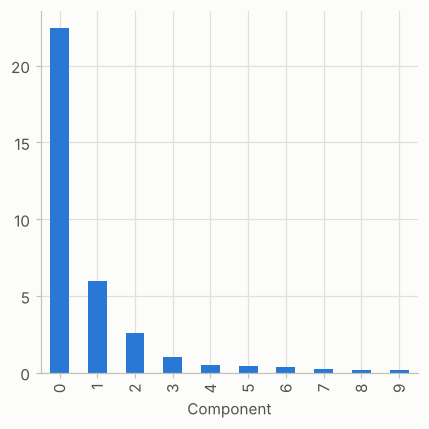

              0         1
GOOGL  0.857310 -0.477873
AMZN   0.444728  0.874149
AAPL   0.071627  0.020802
MSFT   0.036002  0.006204
CSCO   0.029205  0.003045
INTC   0.026666  0.006069
CVX    0.089548  0.037420
XOM    0.080336  0.020511
SLB    0.110218  0.030356
COP    0.057739  0.024117
JPM    0.071228  0.009244
WFC    0.053228  0.008597
USB    0.041670  0.005952
AXP    0.078907  0.024027
WMT    0.040346  0.007141
TGT    0.063659  0.024662
HD     0.051412  0.032922
COST   0.071403  0.033826


In [28]:
# BOOK CODE (Dominant Variables): PCA with two dominant stocks
syms = ['GOOGL', 'AMZN', 'AAPL', 'MSFT', 'CSCO', 'INTC', 'CVX', 'XOM',
        'SLB', 'COP', 'JPM', 'WFC', 'USB', 'AXP', 'WMT', 'TGT', 'HD', 'COST']
top_sp1 = sp500_px.loc[sp500_px.index >= '2005-01-01', syms]

sp_pca1 = PCA()
sp_pca1.fit(top_sp1)

explained_variance = pd.DataFrame(sp_pca1.explained_variance_)
ax = explained_variance.head(10).plot.bar(legend=False, figsize=(4, 4))
ax.set_xlabel('Component')

plt.tight_layout()
plt.show()

loadings = pd.DataFrame(sp_pca1.components_[0:2, :],
                        columns=top_sp1.columns)
print(loadings.transpose())

Categorical data and Gower's distance. The script says that Gower's distance is not available in the standard Python packages; it prints five loans with two numeric and two categorical variables, as in the R example of the book (`loc[0:4]` selects the rows of the defaulted loans with the labels 0 to 4).

In [29]:
# BOOK CODE (Categorical Data and Gower's Distance): five loans with numeric and categorical variables
# > Currently not available in any of the standard packages. However work is in progress to add it to scikit-learn. We will update this notebook once it becomes available
#
# https://github.com/scikit-learn/scikit-learn/pull/9555/

x = defaults[['dti', 'payment_inc_ratio', 'home_', 'purpose_']].loc[0:4, :]
print(x)

     dti  payment_inc_ratio home_            purpose_
0   1.00            2.39320  RENT      major_purchase
1   5.55            4.57170   OWN      small_business
2  18.08            9.71600  RENT               other
3  10.08           12.21520  RENT  debt_consolidation
4   7.06            3.90888  RENT               other


Problems with clustering mixed data. The categorical variables are converted to dummy variables with `pd.get_dummies`, all columns are standardized and K-means finds four clusters; the table has the centres in the original units.

In [30]:
# BOOK CODE (Problems with Clustering Mixed Data): dummy variables and K-means
columns = ['dti', 'payment_inc_ratio', 'home_', 'pub_rec_zero']
df = pd.get_dummies(defaults[columns], dtype=int)

scaler = preprocessing.StandardScaler()

df0 = scaler.fit_transform(df * 1.0)
kmeans = KMeans(n_clusters=4, random_state=1, n_init='auto').fit(df0)
centers = pd.DataFrame(scaler.inverse_transform(kmeans.cluster_centers_),
                       columns=df.columns)
print(centers)

         dti  payment_inc_ratio  pub_rec_zero  home__MORTGAGE     home__OWN    home__RENT
0  21.431365          12.354001      0.943315    1.249001e-14 -1.401657e-15  1.000000e+00
1  12.743276           5.918701      0.900372    1.304512e-14 -3.330669e-16  1.000000e+00
2  17.339786           8.353535      0.905716    1.000000e+00  2.969847e-15  9.547918e-15
3  17.197993           9.266666      0.917903   -2.331468e-15  1.000000e+00 -2.164935e-15


**Output analysis.**

* **Without scaling** the four clusters of the defaulted loans have 13,023, 7,906, 1,654 and 88 loans, and their centres are ordered by income: the average annual income is 41,242, 78,669, 148,736 and 409,746 dollars. The revolving balance rises with it (9,950, 18,933, 33,153 and 84,711) and so does the loan amount (10,274 to 24,291), while the utilization is practically the same in the four clusters (57.9 to 63.2). K-means has divided the loans by income and balance, the variables with the largest numbers, and the 88-loan cluster holds the highest incomes.
* **With scaling** the clusters have 6,244, 3,670, 7,397 and 5,360 loans and are more even and more interesting: cluster 0 has the highest debt-to-income ratio (24.2) with a modest income (55,908); cluster 1 has the largest loans (25,950), incomes (116,834) and balances (32,946); cluster 2 has the highest utilization of the revolving credit (77.8%) and the fewest open accounts (7.5); cluster 3 has the lowest utilization (31.0%) and the lowest balance (6,055).
* **Dominant variables.** The screeplot has one huge first component (a variance of about 22) and a second one of about 6, against about 2.6 for the third and less for the rest. The loadings explain why: the first component is `GOOGL` (0.857) with `AMZN` (0.445), and the second is `AMZN` (0.874) against `GOOGL` (-0.478); no other stock has a loading above 0.110 on the first component or above 0.04 on the second. The two stocks with the largest price changes take the first two components, and the PCA says nothing about the other 16.
* **The five loans** of the table have a debt-to-income ratio between 1.0 and 18.1 and a payment-to-income ratio between 2.4 and 12.2; four of them rent and one (row 1) owns. Loans 2 and 4 have the same two categorical values (`RENT` and `other`), so their Gower distance would come only from the two numeric variables. The script does not compute a distance for them.
* **Mixed data.** The four clusters are almost completely determined by the categorical variable: cluster 0 (`home__RENT` = 1) has a high debt-to-income ratio (21.4) and a high payment ratio (12.4); cluster 1 is also made of renters but with a low ratio (12.7) and low payments (5.9); cluster 2 has only borrowers with a mortgage (`home__MORTGAGE` = 1), and cluster 3 only owners (`home__OWN` = 1). Three of the clusters are simply the three types of home ownership, and the numeric variables only split the renters. `pub_rec_zero` is 0.90 to 0.94 in all clusters and does not separate them. The tiny values such as `1.2e-14` in the table are rounding errors for 0. This is what the Summary describes: the standardized 0-1 variables have a large weight in the distance.

---
## Chapter summary

**Unsupervised learning looks for structure without an outcome.** **PCA** replaces correlated numeric variables by uncorrelated components, ordered by the variance they carry; **correspondence analysis** does the same for a table of counts. **K-means** divides the records into $K$ clusters around their means, **hierarchical clustering** builds a tree of nested clusters from which any $K$ can be cut, and **model-based clustering** fits a mixture of normal distributions and selects the model by BIC. All of them depend on **distances**, so the scale of the variables matters, and categorical variables need a special treatment (dummy variables are problematic, Gower's distance is the alternative).

### Key takeaways

1. The price changes of `XOM` and `CVX` (correlation 0.79) have a first principal component that carries 89.6% of their variance, almost the sum of the two stocks (section 1).
2. For 16 stocks the first principal component (44.5% of the variance) is the whole market, and the second contrasts energy with Apple and retail; the first five carry 80.9% (section 1).
3. In the household tasks, correspondence analysis puts the tasks next to the person who does them; two dimensions carry 88.6% of the inertia (section 1).
4. K-means on 16 stocks gives five clusters of days (strong rises, strong falls, mild rises and two contrasting ones); the elbow plot has no sharp elbow, so the number of clusters is a judgement (section 2).
5. Hierarchical clustering of 18 stocks finds the four energy stocks as a group and isolates `AMZN` and `GOOGL`; single linkage puts 1,127 of 1,131 days in one cluster, Ward's method makes four groups of comparable size (section 3).
6. A two-component Gaussian mixture with its own covariance matrices has the lowest BIC (4,589.8) for the price changes of two stocks: a narrow and a wide cloud of days (section 4).
7. Unscaled K-means divides the defaulted loans by income and balance (one cluster of 88 loans has an income of 410,000 dollars); with standardized variables the clusters differ in the debt-to-income ratio, the utilization and the size of the loan (section 5).
8. Two stocks with large price changes dominate the first two principal components of unstandardized data, and dummy variables dominate the clusters of mixed data (section 5).

### Book vs. library notes

The official code of the chapter ran in this notebook with the versions printed by the setup cell, without changes to the code itself; everything else, in particular what the plots look like, may differ in other versions of the libraries. The differences from the script are:

* **Paths.** The official script finds its data folder with a helper module; here `DATA` comes from the setup cell, which also downloads the files from the official repository if they are missing. The script defines the path of `sp500_sectors.csv` but never reads the file.
* **Seeds.** `KMeans` (in the first two K-means cells, where the script does not set `random_state`) and `GaussianMixture` start from random values and the script has no seed, so the numbering of the clusters and, for the mixtures, the fitted values would change from run to run; those cells start with `np.random.seed(1)  # NOT IN THE BOOK`. The cells with `random_state=0` or `random_state=1` in the script itself, and the hierarchical clustering, are deterministic.
* **Extra cells (not in the book).** Eight short cells marked `# NOT IN THE BOOK` print numbers that the book code only shows in a figure or does not show (the explained variance of the components, the inertia of the correspondence analysis, the centres of the five clusters, the values of the elbow plot, the sizes of the hierarchical clusters, the weights of the mixture and the BIC table); the output analyses use them.
* **`n_init='auto'`.** The comment of the script says that the K-means algorithm is repeated 10 times by default. With `n_init='auto'`, as the script writes it, `KMeans` runs the algorithm once when it uses the default initialization (`k-means++`) and 10 times only for a random initialization, so the clusters of the first cells come from one run (the elbow plot, with `random_state=0`, is also one run for each $K$).
* **`warm_start=True`** in the BIC loop has no effect, because every `GaussianMixture` is created and fitted only once; it would matter only for repeated calls of `fit` on the same object.
* **BIC.** In scikit-learn a **lower** BIC is better, and the code prints and plots it as such.
* **Gower's distance.** The script says that it is not available in the standard packages. In the installed scikit-learn and SciPy it is still not among their distance metrics (`sklearn.metrics.pairwise.distance_metrics()` has `cityblock`, `cosine`, `euclidean`, `haversine`, `l1`, `l2`, `manhattan`, `nan_euclidean` and `precomputed`; `scipy.spatial.distance` has none), so the section has no Python code for it. The R code that the script keeps as comments is not reproduced here.
* **`np.int32(...)`.** `Counter(kmeans.labels_)` shows its keys as `np.int32(4)` and so on in `numpy` 2; the values are the same as before.
* **The data.** The file `sp500_data.csv.gz` holds 5,647 days (from 1993-01-29 to 2015-07-01) for 517 stocks. It has no description of its units; the values behave like daily changes of the price in price units (the standard deviation of the changes of `GOOGL` is 4.2 and that of `XOM` 0.63 over the whole period), not like percentage returns, which is why `GOOGL` and `AMZN` dominate the unscaled analyses.
* **Packages.** `prince` and `adjustText` are not part of a standard Python installation; the setup cell installs them when they are missing. The code ran with `prince` 0.22.2 and `adjustText` 1.4.0; other versions may behave differently or need other code.

---
## References

* Bruce, P., Bruce, A. and Gedeck, P. (2020). *Practical Statistics for Data Scientists: 50+ Essential Concepts Using R and Python*, 2nd edition. O'Reilly Media.
* Official code and data of the book: `gedeck/practical-statistics-for-data-scientists` on GitHub (GNU General Public License v3).
* Arthur, D. and Vassilvitskii, S. (2007). k-means++: the advantages of careful seeding. *Proceedings of the Eighteenth Annual ACM-SIAM Symposium on Discrete Algorithms (SODA '07)*, 1027-1035.
* Dempster, A. P., Laird, N. M. and Rubin, D. B. (1977). Maximum likelihood from incomplete data via the EM algorithm. *Journal of the Royal Statistical Society: Series B*, 39(1), 1-22.
* Gower, J. C. (1971). A general coefficient of similarity and some of its properties. *Biometrics*, 27(4), 857-871.
* Hotelling, H. (1933). Analysis of a complex of statistical variables into principal components. *Journal of Educational Psychology*, 24(6), 417-441 and 24(7), 498-520.
* Lloyd, S. P. (1982). Least squares quantization in PCM. *IEEE Transactions on Information Theory*, 28(2), 129-137.
* Pearson, K. (1901). On lines and planes of closest fit to systems of points in space. *The London, Edinburgh, and Dublin Philosophical Magazine and Journal of Science*, Series 6, 2(11), 559-572.
* Schwarz, G. (1978). Estimating the dimension of a model. *The Annals of Statistics*, 6(2), 461-464.
* Ward, J. H. (1963). Hierarchical grouping to optimize an objective function. *Journal of the American Statistical Association*, 58(301), 236-244.
* The versions of `NumPy`, `pandas`, `SciPy`, `scikit-learn`, `prince`, `adjustText`, `seaborn` and `Matplotlib` are printed by the setup cell.